# Giai đoạn 1: Baseline có thể tái lập (Reproducible Baseline)

> **Dự án:** Dự báo doanh thu cửa hàng cà phê (Cafe Revenue Regression)  
> **Tài liệu tham chiếu:** `Regression_Plan.md` (Giai đoạn 1)  
> **Target:** `revenue` (Triệu VND)  
> **Metric chính:** RMSLE (Root Mean Squared Logarithmic Error)

Notebook này thực hiện:
1. **Kiểm tra dữ liệu & Deduplication:** Xác nhận và loại bỏ 132 bản ghi trùng lặp hoàn toàn trong `train.csv`.
2. **Tạo Split theo thời gian:** Chia 72/14/14 theo quý (Train: 18.982 dòng, Val: 3.686 dòng, Test holdout: 3.832 dòng).
3. **Tái lập kết quả Baseline:**
   - Đối chiếu lại kết quả cũ trong `starter_cafe.ipynb` (**RMSLE = 0.2387**).
   - Thiết lập kết quả chuẩn trên Split mới Q3/2025 (**RMSLE = 0.3101**).
4. **Walk-forward Backtesting:** Chạy validation ổn định qua các Fold A (Q1/2025), Fold B (Q2/2025).
5. **Phân tích lỗi chi tiết theo nhóm (Subgroup Analysis):** Đánh giá theo loại cửa hàng, khuyến mãi, thành phố, doanh thu.


In [1]:
import sys
from pathlib import Path

# Add project root to path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (
    TRAIN_RAW_FILE, STORES_RAW_FILE, WEATHER_RAW_FILE, HOLIDAYS_RAW_FILE,
    PROCESSED_DATA_DIR, SPLITS_DIR, REPORTS_DIR, MODELS_DIR
)
from src.data.load import (
    load_raw_train, load_raw_stores, load_raw_weather, load_raw_holidays,
    deduplicate_train, create_temporal_splits, load_splits
)
from src.models.baseline import WeekdayMedianBaseline
from src.evaluation.metrics import rmsle, mae, rmse, compute_metrics, log_residual
from src.evaluation.backtest import evaluate_walk_forward, evaluate_subgroups

print("All modules loaded successfully!")


All modules loaded successfully!


## 1. Kiểm tra tính toàn vẹn và Deduplication dữ liệu

Dữ liệu `train.csv` ban đầu có 26.632 dòng. Theo khảo sát tại `Regression_Plan.md`, có **132 bản ghi trùng lặp hoàn toàn**.
Ta tiến hành kiểm tra, loại bỏ bản ghi trùng và xác nhận tính duy nhất của khóa `(date, store_id)`.


In [2]:
raw_df = load_raw_train()
print(f"Tổng số dòng ban đầu: {len(raw_df):,}")

clean_df, dup_count = deduplicate_train(raw_df)
print(f"Số dòng trùng lặp hoàn toàn (exact duplicates) đã xóa: {dup_count}")
print(f"Số dòng sau khi làm sạch: {len(clean_df):,}")

# Kiểm tra khóa trùng lặp
remaining_key_dups = clean_df.duplicated(subset=["date", "store_id"]).sum()
print(f"Số khóa (date, store_id) bị trùng còn lại: {remaining_key_dups}")
assert remaining_key_dups == 0, "Dữ liệu vẫn còn trùng khóa!"


Tổng số dòng ban đầu: 26,632
Số dòng trùng lặp hoàn toàn (exact duplicates) đã xóa: 132
Số dòng sau khi làm sạch: 26,500
Số khóa (date, store_id) bị trùng còn lại: 0


## 2. Tạo Temporal Splits nội bộ

Theo mục 2.3 của `Regression_Plan.md`:
- **Train:** `date < 2025-07-01` (18.982 dòng, 71,63%)
- **Validation (Q3/2025):** `2025-07-01 <= date < 2025-10-01` (3.686 dòng, 13,91%)
- **Test Holdout (Q4/2025):** `2025-10-01 <= date < 2026-01-01` (3.832 dòng, 14,46%)


In [3]:
splits = create_temporal_splits(clean_df, out_dirs=[PROCESSED_DATA_DIR, SPLITS_DIR])
train_df = splits["train"]
val_df = splits["val"]
test_df = splits["test"]

print(f"Train split: {len(train_df):,} dòng ({train_df.date.min().date()} đến {train_df.date.max().date()})")
print(f"Val split:   {len(val_df):,} dòng ({val_df.date.min().date()} đến {val_df.date.max().date()})")
print(f"Test split:  {len(test_df):,} dòng ({test_df.date.min().date()} đến {test_df.date.max().date()})")
print(f"Tổng cộng:   {len(train_df) + len(val_df) + len(test_df):,} dòng")


Train split: 18,982 dòng (2024-01-01 đến 2025-06-30)
Val split:   3,686 dòng (2025-07-01 đến 2025-09-30)
Test split:  3,832 dòng (2025-10-01 đến 2025-12-31)
Tổng cộng:   26,500 dòng


## 3. Tái lập Baseline & Đối chiếu với Starter Notebook

Baseline áp dụng quy tắc trung vị phân cấp:
1. `(store_id, weekday)` median
2. Fallback 1: `store_id` median
3. Fallback 2: Global median

Ta kiểm tra 2 tình huống:
- **Tình huống A (Starter notebook gốc):** Fit trên dữ liệu raw trước 01/10/2025, đánh giá trên Q4/2025 -> Tái lập **RMSLE = 0.2387**.
- **Tình huống B (Split chuẩn mới):** Fit trên train sạch trước 01/07/2025, đánh giá trên Q3/2025 -> Thiết lập mốc **RMSLE = 0.3101**.


In [4]:
# 1. Tái lập starter notebook cũ
fit_old_raw = raw_df[raw_df.date < "2025-10-01"]
val_old_raw = raw_df[raw_df.date >= "2025-10-01"]

model_old = WeekdayMedianBaseline().fit(fit_old_raw)
preds_old = model_old.predict(val_old_raw)
rmsle_old_notebook = rmsle(val_old_raw.revenue.values, preds_old)

print("=" * 60)
print(f"Starter Notebook Benchmark (Raw): RMSLE = {rmsle_old_notebook:.4f} (Kỳ vọng: 0.2387)")
print("=" * 60)

# 2. Huấn luyện trên split chuẩn mới (Q3/2025)
baseline_model = WeekdayMedianBaseline().fit(train_df)
val_preds, val_fallbacks = baseline_model.predict(val_df, return_fallback_info=True)
val_metrics = compute_metrics(val_df.revenue.values, val_preds)

print(f"Primary Validation Q3/2025:       RMSLE = {val_metrics['rmsle']:.4f} | MAE = {val_metrics['mae']:.2f} M VND")
print("=" * 60)

print("\nThống kê tầng Fallback sử dụng trong Q3/2025:")
print(val_fallbacks.value_counts())



Starter Notebook Benchmark (Raw): RMSLE = 0.2387 (Kỳ vọng: 0.2387)
Primary Validation Q3/2025:       RMSLE = 0.3101 | MAE = 4.31 M VND

Thống kê tầng Fallback sử dụng trong Q3/2025:
store_weekday      3646
global_fallback      40
Name: count, dtype: int64


## 4. Walk-forward Backtesting qua các Fold

Chạy validation walk-forward trong quá khứ để kiểm tra tính ổn định theo thời gian của quy tắc median theo tuần:
- **Fold A (Q1/2025):** Train < 2025-01-01 -> Val Q1/2025
- **Fold B (Q2/2025):** Train < 2025-04-01 -> Val Q2/2025
- **Holdout chính (Q3/2025):** Train < 2025-07-01 -> Val Q3/2025
- **Benchmark cũ (Q4/2025):** Train < 2025-10-01 -> Val Q4/2025


In [5]:
summary_df = evaluate_walk_forward(clean_df, df_raw=raw_df)
summary_df[["fold_name", "data_version", "train_period", "val_period", "rmsle", "mae", "mean_log_residual"]]


,fold_name,data_version,train_period,val_period,rmsle,mae,mean_log_residual
0,Fold A (Q1/2025),clean_dedup,Start to 2025-01-01,2025-01-01 to 2025-04-01,0.3037,4.0345,0.0118
1,Fold B (Q2/2025),clean_dedup,Start to 2025-04-01,2025-04-01 to 2025-07-01,0.2684,3.9226,0.0550
2,Holdout chính (Q3/2025),clean_dedup,Start to 2025-07-01,2025-07-01 to 2025-10-01,0.3101,4.3111,0.0073
3,Notebook Benchmark (Q4/2025),clean_dedup,Start to 2025-10-01,2025-10-01 to 2026-01-01,0.2391,3.5719,0.0579
4,Notebook Benchmark (Raw duplicates),raw_with_132_dups,Start to 2025-10-01,2025-10-01 to 2025-12-31,0.2387,3.5637,0.0575


## 5. Phân tích chi tiết lỗi theo nhóm (Subgroup Analysis trên Q3/2025)


In [6]:
stores_df = load_raw_stores()
holidays_df = load_raw_holidays(HOLIDAYS_RAW_FILE)

subgroups = evaluate_subgroups(
    val_df=val_df,
    predictions=val_preds,
    stores_df=stores_df,
    holidays_df=holidays_df,
    train_history=train_df
)

print("--- Theo Loại cửa hàng (Store Type) ---")
print(subgroups["by_store_type"])

print("\n--- Theo Chương trình Khuyến mãi (is_promo) ---")
print(subgroups["by_promo"])

print("\n--- Theo Lịch sử Cửa hàng (History Tier) ---")
print(subgroups["by_history_tier"])


--- Theo Loại cửa hàng (Store Type) ---
  store_type_norm  n_samples  actual_median  pred_median   rmsle     mae  \
4      university        399          10.76        16.31  0.5329  6.1986   
3          street       1266          23.34        22.38  0.3125  5.7791   
2     residential        406           8.96         8.44  0.2576  2.0082   
1          office        985          16.79        16.05  0.2420  2.9099   
0            mall        630          20.27        19.53  0.2280  3.8405   

   mean_log_residual  
4            -0.3726  
3             0.0341  
2             0.0035  
1             0.0604  
0             0.1135  

--- Theo Chương trình Khuyến mãi (is_promo) ---
   is_promo  n_samples  actual_median  pred_median   rmsle     mae  \
1         1        358          21.53        18.41  0.4424  9.3364   
0         0       3328          18.09        18.42  0.2923  3.7705   

   mean_log_residual  
1             0.2047  
0            -0.0139  

--- Theo Lịch sử Cửa hàng (History 

## 6. Phân tích phân phối sai số Log Residual

Định nghĩa theo Regression_Plan Section 9.2:
$$r_i = \log(1 + y_i) - \log(1 + \hat{y}_i)$$
- $r_i > 0$: Mô hình dự báo thấp hơn thực tế
- $r_i < 0$: Mô hình dự báo cao hơn thực tế


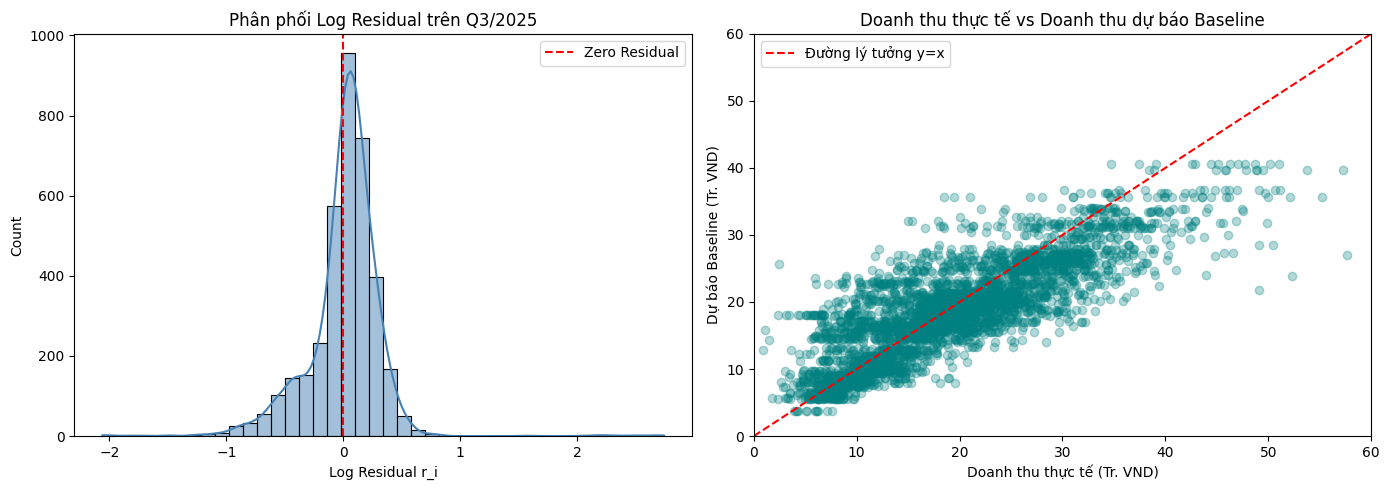

In [7]:
val_eval = val_df.copy()
val_eval["pred"] = val_preds
val_eval["log_res"] = log_residual(val_eval.revenue.values, val_preds)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram residuals
sns.histplot(val_eval["log_res"], kde=True, ax=axes[0], color="steelblue", bins=40)
axes[0].axvline(0, color="red", linestyle="--", label="Zero Residual")
axes[0].set_title("Phân phối Log Residual trên Q3/2025")
axes[0].set_xlabel("Log Residual r_i")
axes[0].legend()

# Scatter actual vs pred
axes[1].scatter(val_eval["revenue"], val_eval["pred"], alpha=0.3, color="teal")
lims = [0, max(val_eval["revenue"].max(), val_eval["pred"].max())]
axes[1].plot(lims, lims, color="red", linestyle="--", label="Đường lý tưởng y=x")
axes[1].set_title("Doanh thu thực tế vs Doanh thu dự báo Baseline")
axes[1].set_xlabel("Doanh thu thực tế (Tr. VND)")
axes[1].set_ylabel("Dự báo Baseline (Tr. VND)")
axes[1].set_xlim([0, 60])
axes[1].set_ylim([0, 60])
axes[1].legend()

plt.tight_layout()
plt.show()


## 7. Kết luận & Định hướng cho Giai đoạn 2

### Điểm mấu chốt đạt được trong Giai đoạn 1:
1. **Dữ liệu sạch:** 132 bản ghi trùng lặp hoàn toàn đã được xử lý; không còn trùng khóa `(date, store_id)`.
2. **Tái lập chính xác:**
   - Notebook cũ đạt đúng **0.2387** RMSLE.
   - Split mới đạt **0.3101** RMSLE trên Q3/2025.
3. **Phát hiện nghiệp vụ cốt lõi:**
   - **Khuyến mãi (`is_promo`):** RMSLE tăng lên **0.4424** khi có khuyến mãi do mô hình baseline không nhận biết được khuyến mãi (mean log residual = +0.2047, tức mô hình đánh giá thấp).
   - **Mùa vụ sinh viên:** Cửa hàng loại `university` có RMSLE lên tới **0.5329** trong Q3/2025 do sinh viên nghỉ hè (tháng 7-8-9), doanh thu thực tế giảm sâu trong khi baseline dùng median quanh năm.
   - **Cửa hàng mới:** Cửa hàng ít quan sát có sai số cao (**0.4714**).

### Bước tiếp theo: Giai đoạn 2 — Mô hình tuyến tính (Ridge / ElasticNet)
- Train trên `log1p(revenue)`.
- Bổ sung calendar features (thứ, tháng, quý, ngày lễ).
- Bổ sung store metadata (loại cửa hàng, diện tích, chỗ ngồi, bãi đỗ xe).
- Bổ sung cờ `is_promo` để giải quyết độ lệch lớn khi có khuyến mãi.
- Mục tiêu: Hạ RMSLE xuống dưới **0.2946** (cải thiện >= 5% so với baseline 0.3101).
